# Assignment 1

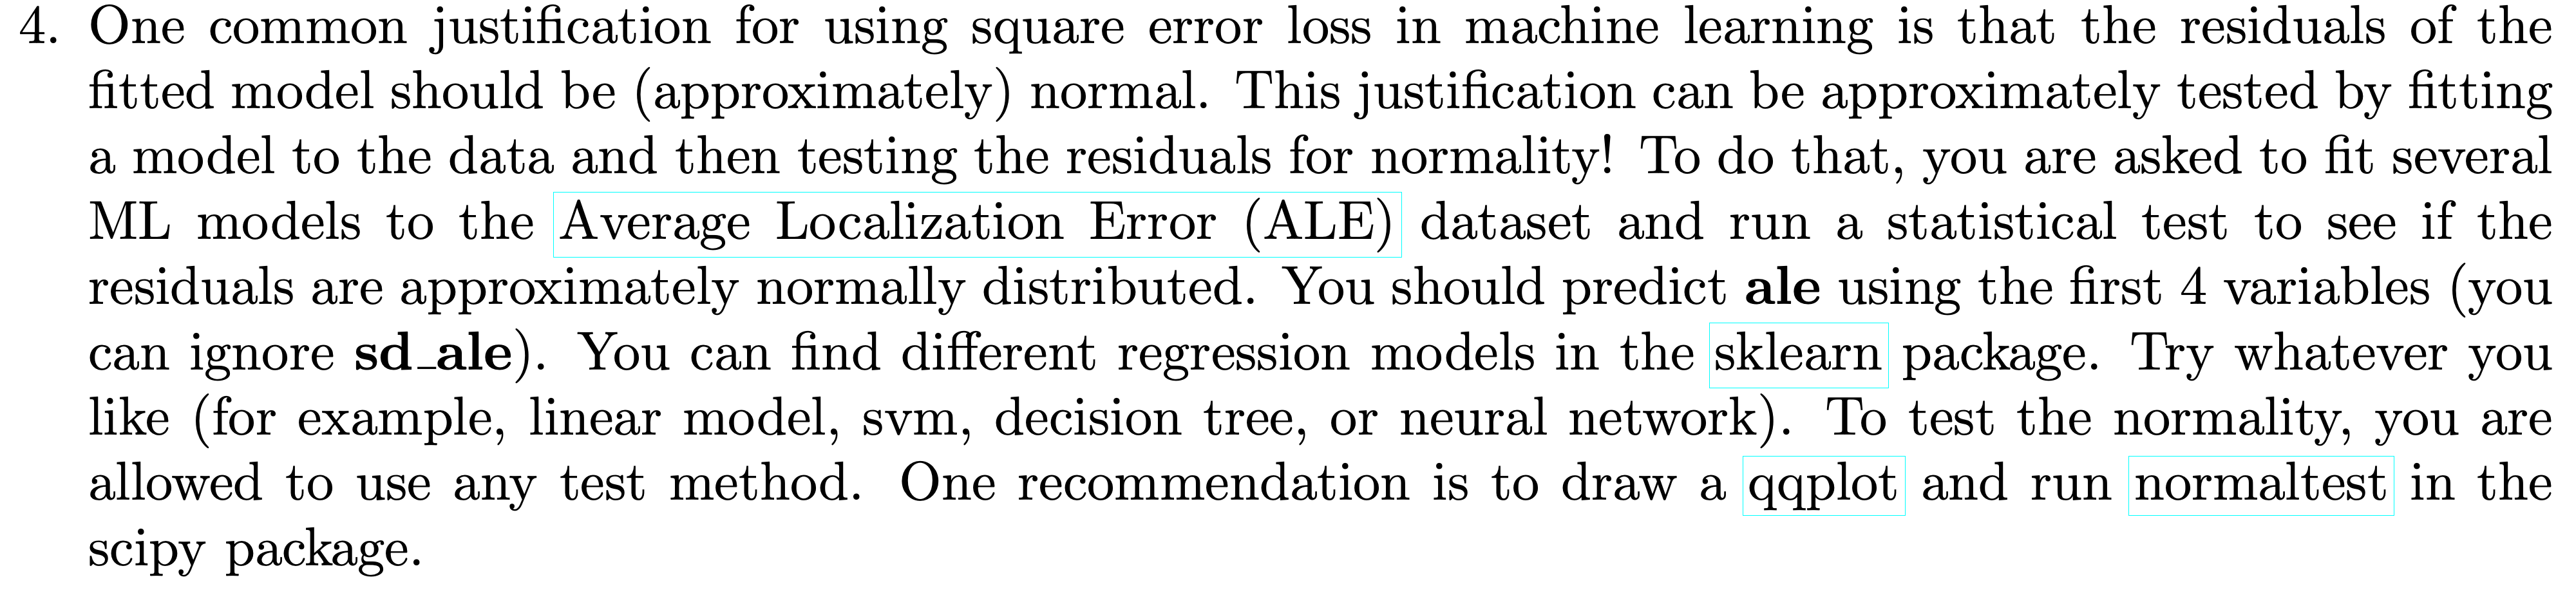

In [94]:
import pandas as pd

ale_data = pd.read_csv("mcs_ds_edited_iter_shuffled.csv")##["column_1", "column_2"]

ale_data.drop("sd_ale", axis=1, inplace=True)
ale_data.head(5)

,anchor_ratio,trans_range,node_density,iterations,ale
0,30,15,200,40,0.773546
1,15,15,100,70,0.911941
2,30,15,100,50,0.814867
3,15,20,100,20,1.435332
4,30,15,100,40,1.265909


In [95]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from scipy import stats

X = ale_data.iloc[:, 0:4]    # predictors 
y = ale_data["ale"]         # target (sd_ale is ignored)

In [96]:
X

,anchor_ratio,trans_range,node_density,iterations
0,30,15,200,40
1,15,15,100,70
2,30,15,100,50
3,15,20,100,20
4,30,15,100,40
...,...,...,...,...
102,18,23,100,20
103,14,17,200,60
104,15,20,100,50
105,20,20,100,40


# Split data in training and test set

In [97]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

Linear: p-value = 1.287e-09


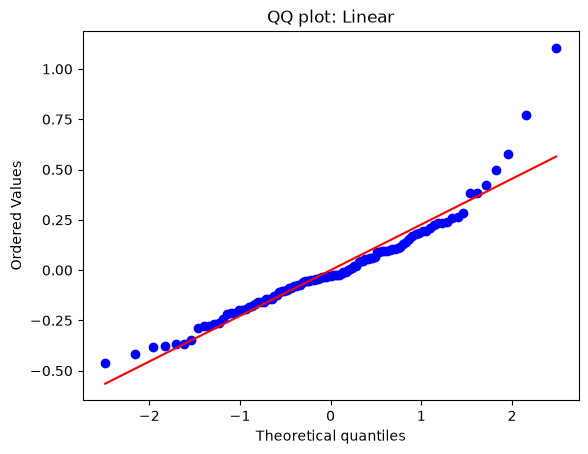

Decision Tree: p-value = 0.004367


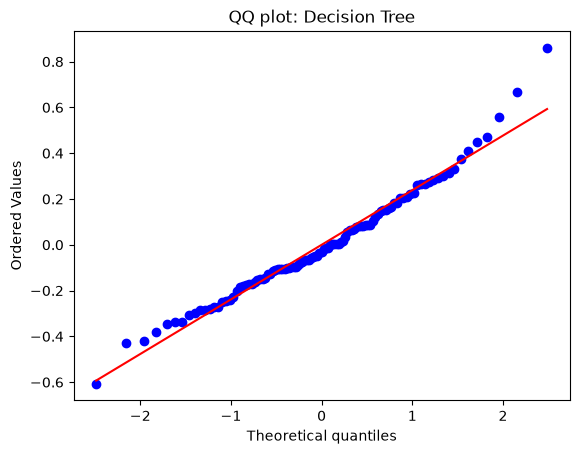

SVR: p-value = 2.321e-11


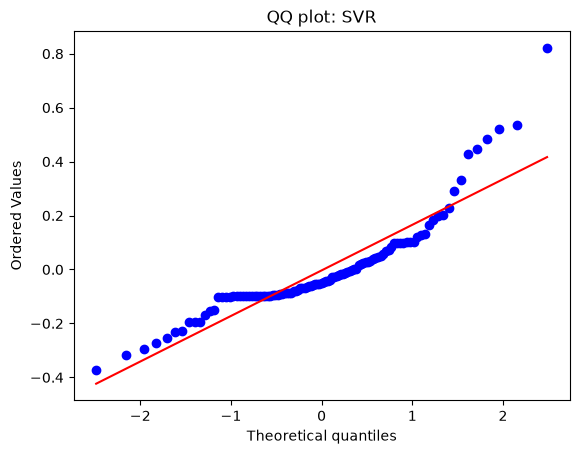

Neural Net: p-value = 4.206e-06


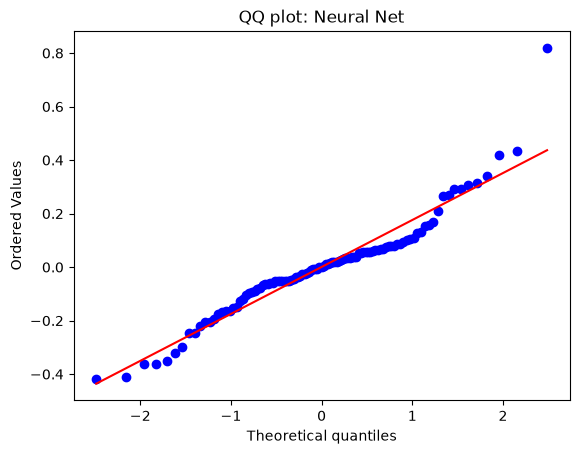

In [98]:
from sklearn.linear_model import LinearRegression
from sklearn.tree import DecisionTreeRegressor
from sklearn.svm import SVR
from sklearn.neural_network import MLPRegressor
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler

models = {
    "Linear": LinearRegression(),
    "Decision Tree": DecisionTreeRegressor(max_depth=2, random_state=42),
    "SVR": make_pipeline(StandardScaler(), SVR()),
    "Neural Net": make_pipeline(StandardScaler(),
                                MLPRegressor(hidden_layer_sizes=(50, 50),
                                             max_iter=2000, random_state=42)),
}

for name, model in models.items():
    model.fit(X, y)
    pred = model.predict(X)
    residuals = y - pred

    # normality test (null hypothesis: residuals are normal)
    stat, p = stats.normaltest(residuals)
    print(f"{name}: p-value = {p:.4g}")

    # QQ plot
    stats.probplot(residuals, dist="norm", plot=plt)
    plt.title(f"QQ plot: {name}")
    plt.show()

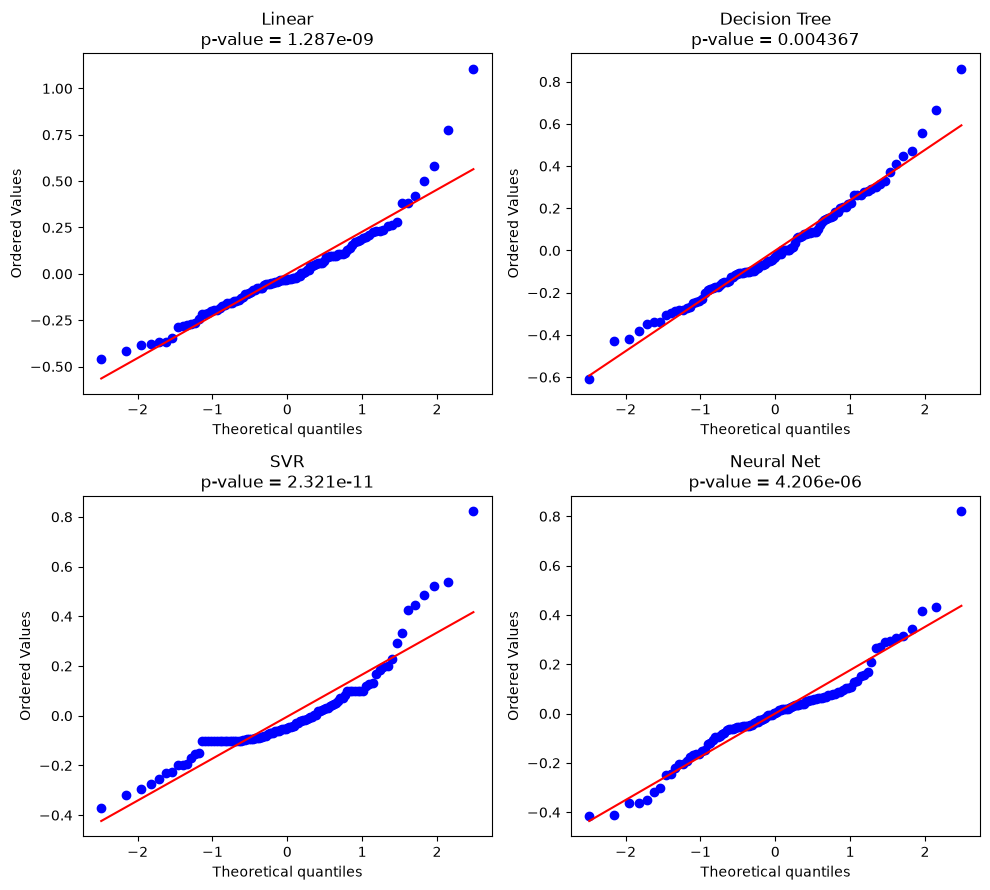

           Model  Statistic       p-value
0         Linear  40.942406  1.286677e-09
1  Decision Tree  10.867482  4.366729e-03
2            SVR  48.972624  2.321293e-11
3     Neural Net  24.757815  4.206383e-06


In [99]:
import matplotlib.pyplot as plt
import pandas as pd
from scipy import stats

resultados = []

fig, axes = plt.subplots(2, 2, figsize=(10, 9))
axes = axes.flatten()

for ax, (name, model) in zip(axes, models.items()):
    model.fit(X, y)
    pred = model.predict(X)
    residuals = y - pred

    stat, p = stats.normaltest(residuals)
    resultados.append({"Model": name, "Statistic": stat, "p-value": p})

    stats.probplot(residuals, dist="norm", plot=ax)
    ax.set_title(f"{name}\np-value = {p:.4g}")

plt.tight_layout()
plt.savefig("qqplots.png", dpi=300, bbox_inches="tight")
plt.show()

tabla = pd.DataFrame(resultados)
print(tabla)
tabla.to_csv("pvalues.csv", index=False)

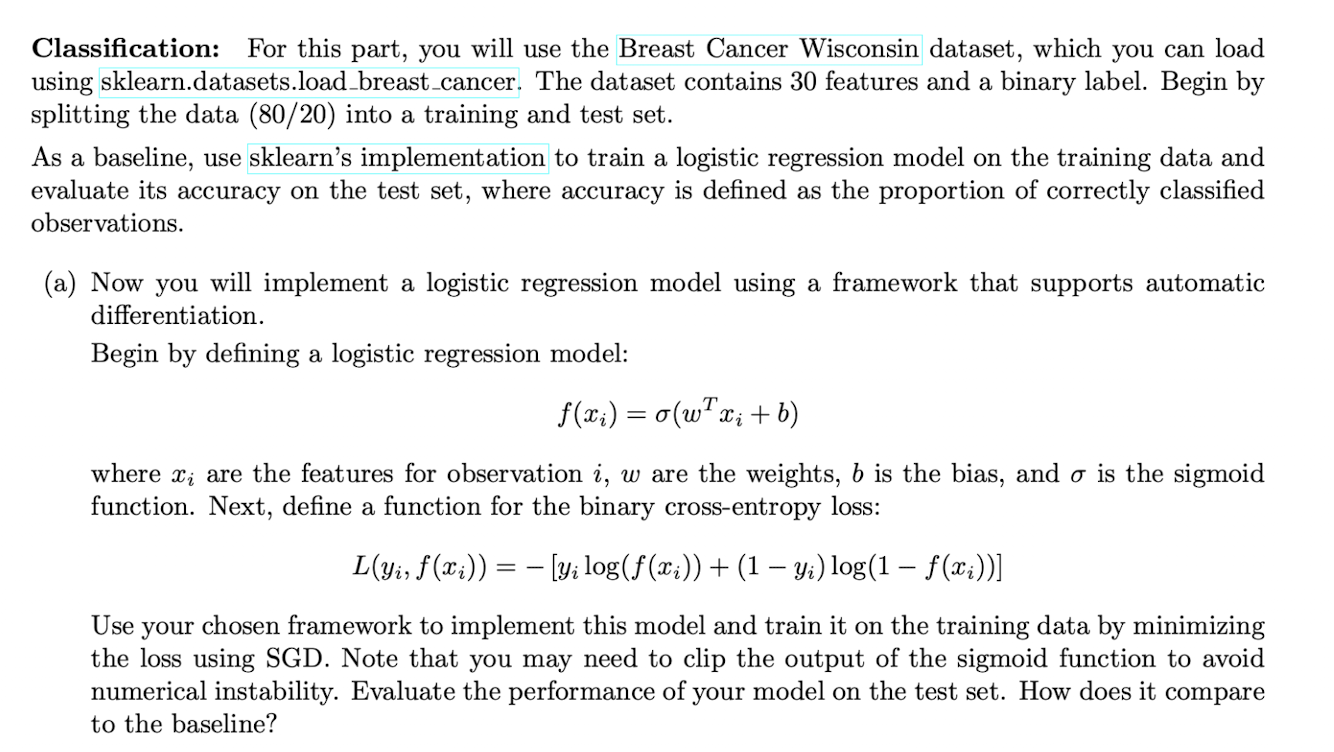

In [100]:
from sklearn.datasets import load_breast_cancer

data = load_breast_cancer(as_frame=True)

X = data.data    
y = data.target    

print(X.shape, y.shape)
print(data.feature_names)
print(data.target_names)

(569, 30) (569,)
['mean radius' 'mean texture' 'mean perimeter' 'mean area'
 'mean smoothness' 'mean compactness' 'mean concavity'
 'mean concave points' 'mean symmetry' 'mean fractal dimension'
 'radius error' 'texture error' 'perimeter error' 'area error'
 'smoothness error' 'compactness error' 'concavity error'
 'concave points error' 'symmetry error' 'fractal dimension error'
 'worst radius' 'worst texture' 'worst perimeter' 'worst area'
 'worst smoothness' 'worst compactness' 'worst concavity'
 'worst concave points' 'worst symmetry' 'worst fractal dimension']
['malignant' 'benign']


In [101]:
data

{'data':      mean radius  mean texture  mean perimeter  mean area  mean smoothness  \
 0          17.99         10.38          122.80     1001.0          0.11840   
 1          20.57         17.77          132.90     1326.0          0.08474   
 2          19.69         21.25          130.00     1203.0          0.10960   
 3          11.42         20.38           77.58      386.1          0.14250   
 4          20.29         14.34          135.10     1297.0          0.10030   
 ..           ...           ...             ...        ...              ...   
 564        21.56         22.39          142.00     1479.0          0.11100   
 565        20.13         28.25          131.20     1261.0          0.09780   
 566        16.60         28.08          108.30      858.1          0.08455   
 567        20.60         29.33          140.10     1265.0          0.11780   
 568         7.76         24.54           47.92      181.0          0.05263   
 
      mean compactness  mean concavity  me

# Split the data 80-20 and obtain baseline data

In [102]:
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import accuracy_score

X_train, X_test, y_train, y_test = train_test_split(
     X, y, test_size=0.2, random_state=42
)

model = make_pipeline(StandardScaler(), LogisticRegression(max_iter=1000))
model.fit(X_train, y_train)

y_pred = model.predict(X_test)
baseline_acc = accuracy_score(y_test, y_pred)
print(f"Baseline test accuracy: {baseline_acc:.4f}")


Baseline test accuracy: 0.9737


In [103]:
import torch
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()
X_train_s = scaler.fit_transform(X_train)
X_test_s = scaler.transform(X_test)

X_train_t = torch.tensor(X_train_s, dtype=torch.float32)
X_test_t = torch.tensor(X_test_s, dtype=torch.float32)
y_train_t = torch.tensor(y_train.values, dtype=torch.float32)
y_test_t = torch.tensor(y_test.values, dtype=torch.float32)

torch.manual_seed(42)
n_features = X_train_t.shape[1]

def f_logistic(x):
    p = torch.sigmoid(x @ w + b) # w is a vector of weights (theta)
    return torch.clamp(p, 1e-7, 1 - 1e-7)

def bce_loss(y, p):
    return -(y * torch.log(p) + (1 - y) * torch.log(1 - p)).mean() # calculates the cross-entropy-loss



In [104]:
w = torch.zeros(n_features, requires_grad=True)
b = torch.zeros(1, requires_grad=True)
optimizer = torch.optim.SGD([w, b], lr=0.1)

n_epochs = 1000
batch_size = 42
n = X_train_t.shape[0]

for epoch in range(n_epochs):
    perm = torch.randperm(n)                     
    for i in range(0, n, batch_size): 
        idx = perm[i:i + batch_size] 
        xb, yb = X_train_t[idx], y_train_t[idx] 

        loss = bce_loss(yb, f_logistic(xb)) #computes the loss using yb and the function we defined earlier

        optimizer.zero_grad()   # clear old gradients
        loss.backward()         # autodiff computes dL/dw and dL/db
        optimizer.step()        # w <- w - lr * grad

    if (epoch + 1) % 20 == 0:
        with torch.no_grad():
            full_loss = bce_loss(y_train_t, f_logistic(X_train_t))
        print(f"Epoch {epoch+1}: train loss = {full_loss:.4f}")

Epoch 20: train loss = 0.0854
Epoch 40: train loss = 0.0724
Epoch 60: train loss = 0.0665
Epoch 80: train loss = 0.0628
Epoch 100: train loss = 0.0602
Epoch 120: train loss = 0.0583
Epoch 140: train loss = 0.0567
Epoch 160: train loss = 0.0555
Epoch 180: train loss = 0.0544
Epoch 200: train loss = 0.0535
Epoch 220: train loss = 0.0528
Epoch 240: train loss = 0.0521
Epoch 260: train loss = 0.0515
Epoch 280: train loss = 0.0509
Epoch 300: train loss = 0.0504
Epoch 320: train loss = 0.0500
Epoch 340: train loss = 0.0496
Epoch 360: train loss = 0.0492
Epoch 380: train loss = 0.0488
Epoch 400: train loss = 0.0485
Epoch 420: train loss = 0.0482
Epoch 440: train loss = 0.0479
Epoch 460: train loss = 0.0476
Epoch 480: train loss = 0.0473
Epoch 500: train loss = 0.0470
Epoch 520: train loss = 0.0468
Epoch 540: train loss = 0.0465
Epoch 560: train loss = 0.0463
Epoch 580: train loss = 0.0461
Epoch 600: train loss = 0.0459
Epoch 620: train loss = 0.0457
Epoch 640: train loss = 0.0455
Epoch 660: t

In [105]:
with torch.no_grad():
    probs = f_logistic(X_test_t)
    preds = (probs >= 0.5).float()
    sgd_acc = (preds == y_test_t).float().mean().item()

print(f"Baseline (sklearn) accuracy: {baseline_acc:.4f}")
print(f"Autodiff + SGD accuracy:     {sgd_acc:.4f}")

Baseline (sklearn) accuracy: 0.9737
Autodiff + SGD accuracy:     0.9825


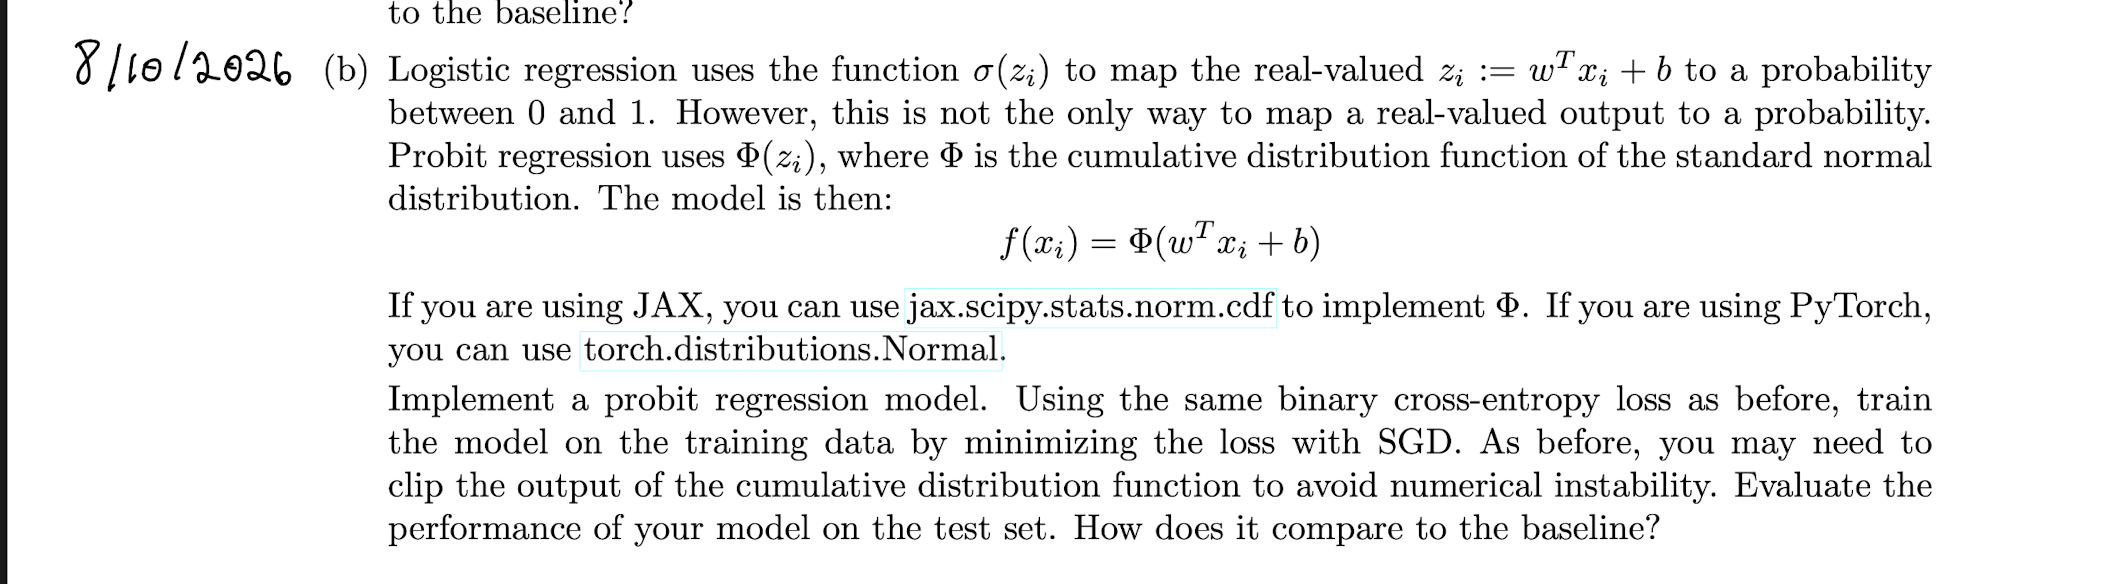

In [106]:
def f_probit(x):
    z = x @ w + b
    p = torch.distributions.Normal(0.0, 1.0).cdf(z)
    return torch.clamp(p, 1e-7, 1 - 1e-7) 

w = torch.zeros(n_features, requires_grad=True)
b = torch.zeros(1, requires_grad=True)

optimizer = torch.optim.SGD([w, b], lr=0.1)

n_epochs = 1000
batch_size = 42
n = X_train_t.shape[0]

for epoch in range(n_epochs):
    perm = torch.randperm(n)                      # shuffle each epoch does a random permutation of the data
    for i in range(0, n, batch_size): #takes batches in 42 by 42 samples 
        idx = perm[i:i + batch_size] 
        xb, yb = X_train_t[idx], y_train_t[idx]  #obtains the training features and labels to obtain the loss 

        loss = bce_loss(yb, f_probit(xb)) #computes the loss using yb and the function we defined earlier

        optimizer.zero_grad()   # clear old gradients
        loss.backward()         # autodiff computes dL/dw and dL/db
        optimizer.step()        # w <- w - lr * grad

    if (epoch + 1) % 20 == 0:
        with torch.no_grad():
            full_loss = bce_loss(y_train_t, f_probit(X_train_t))
        print(f"Epoch {epoch+1}: train loss = {full_loss:.4f}")

Epoch 20: train loss = 0.0677
Epoch 40: train loss = 0.0597
Epoch 60: train loss = 0.0559
Epoch 80: train loss = 0.0534
Epoch 100: train loss = 0.0516
Epoch 120: train loss = 0.0502
Epoch 140: train loss = 0.0490
Epoch 160: train loss = 0.0480
Epoch 180: train loss = 0.0472
Epoch 200: train loss = 0.0464
Epoch 220: train loss = 0.0457
Epoch 240: train loss = 0.0450
Epoch 260: train loss = 0.0444
Epoch 280: train loss = 0.0438
Epoch 300: train loss = 0.0433
Epoch 320: train loss = 0.0428
Epoch 340: train loss = 0.0424
Epoch 360: train loss = 0.0419
Epoch 380: train loss = 0.0415
Epoch 400: train loss = 0.0411
Epoch 420: train loss = 0.0407
Epoch 440: train loss = 0.0404
Epoch 460: train loss = 0.0400
Epoch 480: train loss = 0.0397
Epoch 500: train loss = 0.0394
Epoch 520: train loss = 0.0391
Epoch 540: train loss = 0.0388
Epoch 560: train loss = 0.0385
Epoch 580: train loss = 0.0382
Epoch 600: train loss = 0.0380
Epoch 620: train loss = 0.0377
Epoch 640: train loss = 0.0375
Epoch 660: t

In [107]:
with torch.no_grad():
    probs = f_probit(X_test_t)
    preds = (probs >= 0.5).float()
    sgd_acc = (preds == y_test_t).float().mean().item()

print(f"Baseline (sklearn) accuracy: {baseline_acc:.4f}")
print(f"Autodiff + SGD accuracy:     {sgd_acc:.4f}")

Baseline (sklearn) accuracy: 0.9737
Autodiff + SGD accuracy:     0.9649


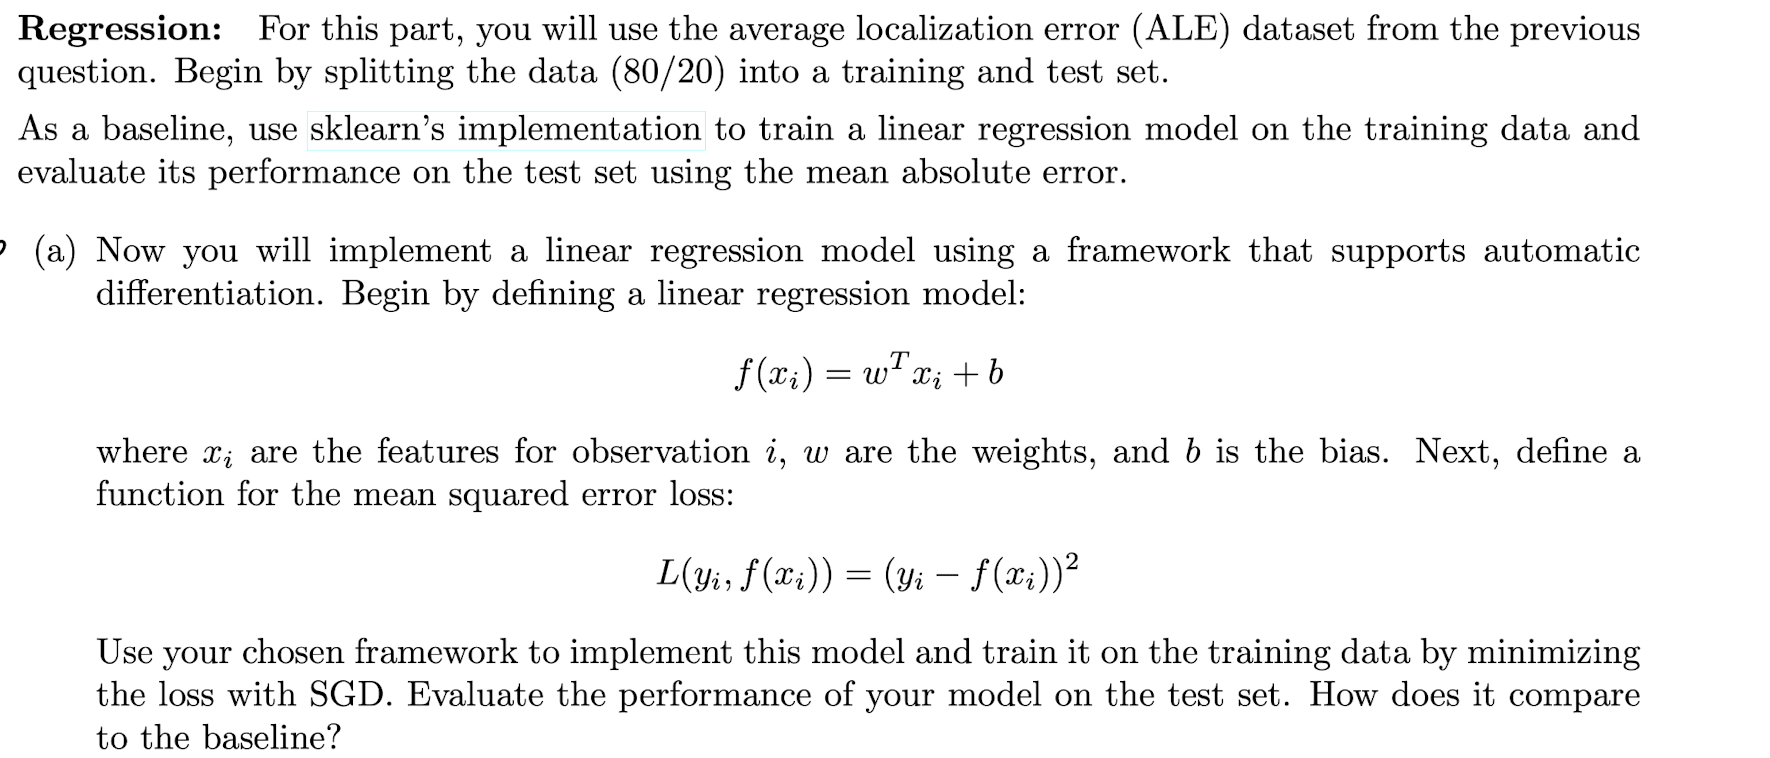

# Baseline Calculation

In [108]:
from sklearn.metrics import mean_absolute_error

X = ale_data.iloc[:, 0:4]    # predictors 
y = ale_data["ale"]      

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)
lin = LinearRegression().fit(X_train, y_train)
baseline_mae = mean_absolute_error(y_test, lin.predict(X_test))
print(f"Baseline MAE: {baseline_mae:.4f}")


Baseline MAE: 0.1954


In [109]:
scaler = StandardScaler()
X_train_s = scaler.fit_transform(X_train)
X_test_s = scaler.transform(X_test)

X_train_t = torch.tensor(X_train_s, dtype=torch.float32)
X_test_t = torch.tensor(X_test_s, dtype=torch.float32)
y_train_t = torch.tensor(y_train.values, dtype=torch.float32)
y_test_t = torch.tensor(y_test.values, dtype=torch.float32)

torch.manual_seed(42)
n_features = X_train_t.shape[1]

w = torch.zeros(n_features, requires_grad=True)
b = torch.zeros(1, requires_grad=True)

def f_linear(x):
    y_hat = x @ w + b
    return y_hat

def mse_loss(y, pred):
    return ((y - pred) ** 2).mean()


In [110]:
w = torch.zeros(n_features, requires_grad=True)
b = torch.zeros(1, requires_grad=True)

optimizer = torch.optim.SGD([w, b], lr=0.1)

n_epochs = 100
batch_size = 50
n = X_train_t.shape[0]

for epoch in range(n_epochs):
    perm = torch.randperm(n)                      # shuffle each epoch does a random permutation of the data
    for i in range(0, n, batch_size): 
        idx = perm[i:i + batch_size] 
        xb, yb = X_train_t[idx], y_train_t[idx]  #obtains the training features and labels to obtain the loss 

        loss = mse_loss(yb, f_linear(xb)) #computes the loss using yb and the function we defined earlier

        optimizer.zero_grad()   # clear old gradients
        loss.backward()         # autodiff computes dL/dw and dL/db
        optimizer.step()        

    if (epoch + 1) % 20 == 0:
        with torch.no_grad():
            full_loss = mse_loss(y_train_t, f_linear(X_train_t))
        print(f"Epoch {epoch+1}: train loss = {full_loss:.4f}")

Epoch 20: train loss = 0.0506
Epoch 40: train loss = 0.0507
Epoch 60: train loss = 0.0506
Epoch 80: train loss = 0.0507
Epoch 100: train loss = 0.0506


In [111]:
with torch.no_grad():
    fit_linear = f_linear(X_test_t)
    pred_mae = mean_absolute_error(y_test, fit_linear.numpy())

print(f"Baseline (sklearn) mean absolute error: {baseline_mae:.4f}")
print(f"Autodiff + SGD mean absolute error:     {pred_mae:.4f}")

Baseline (sklearn) mean absolute error: 0.1954
Autodiff + SGD mean absolute error:     0.1946


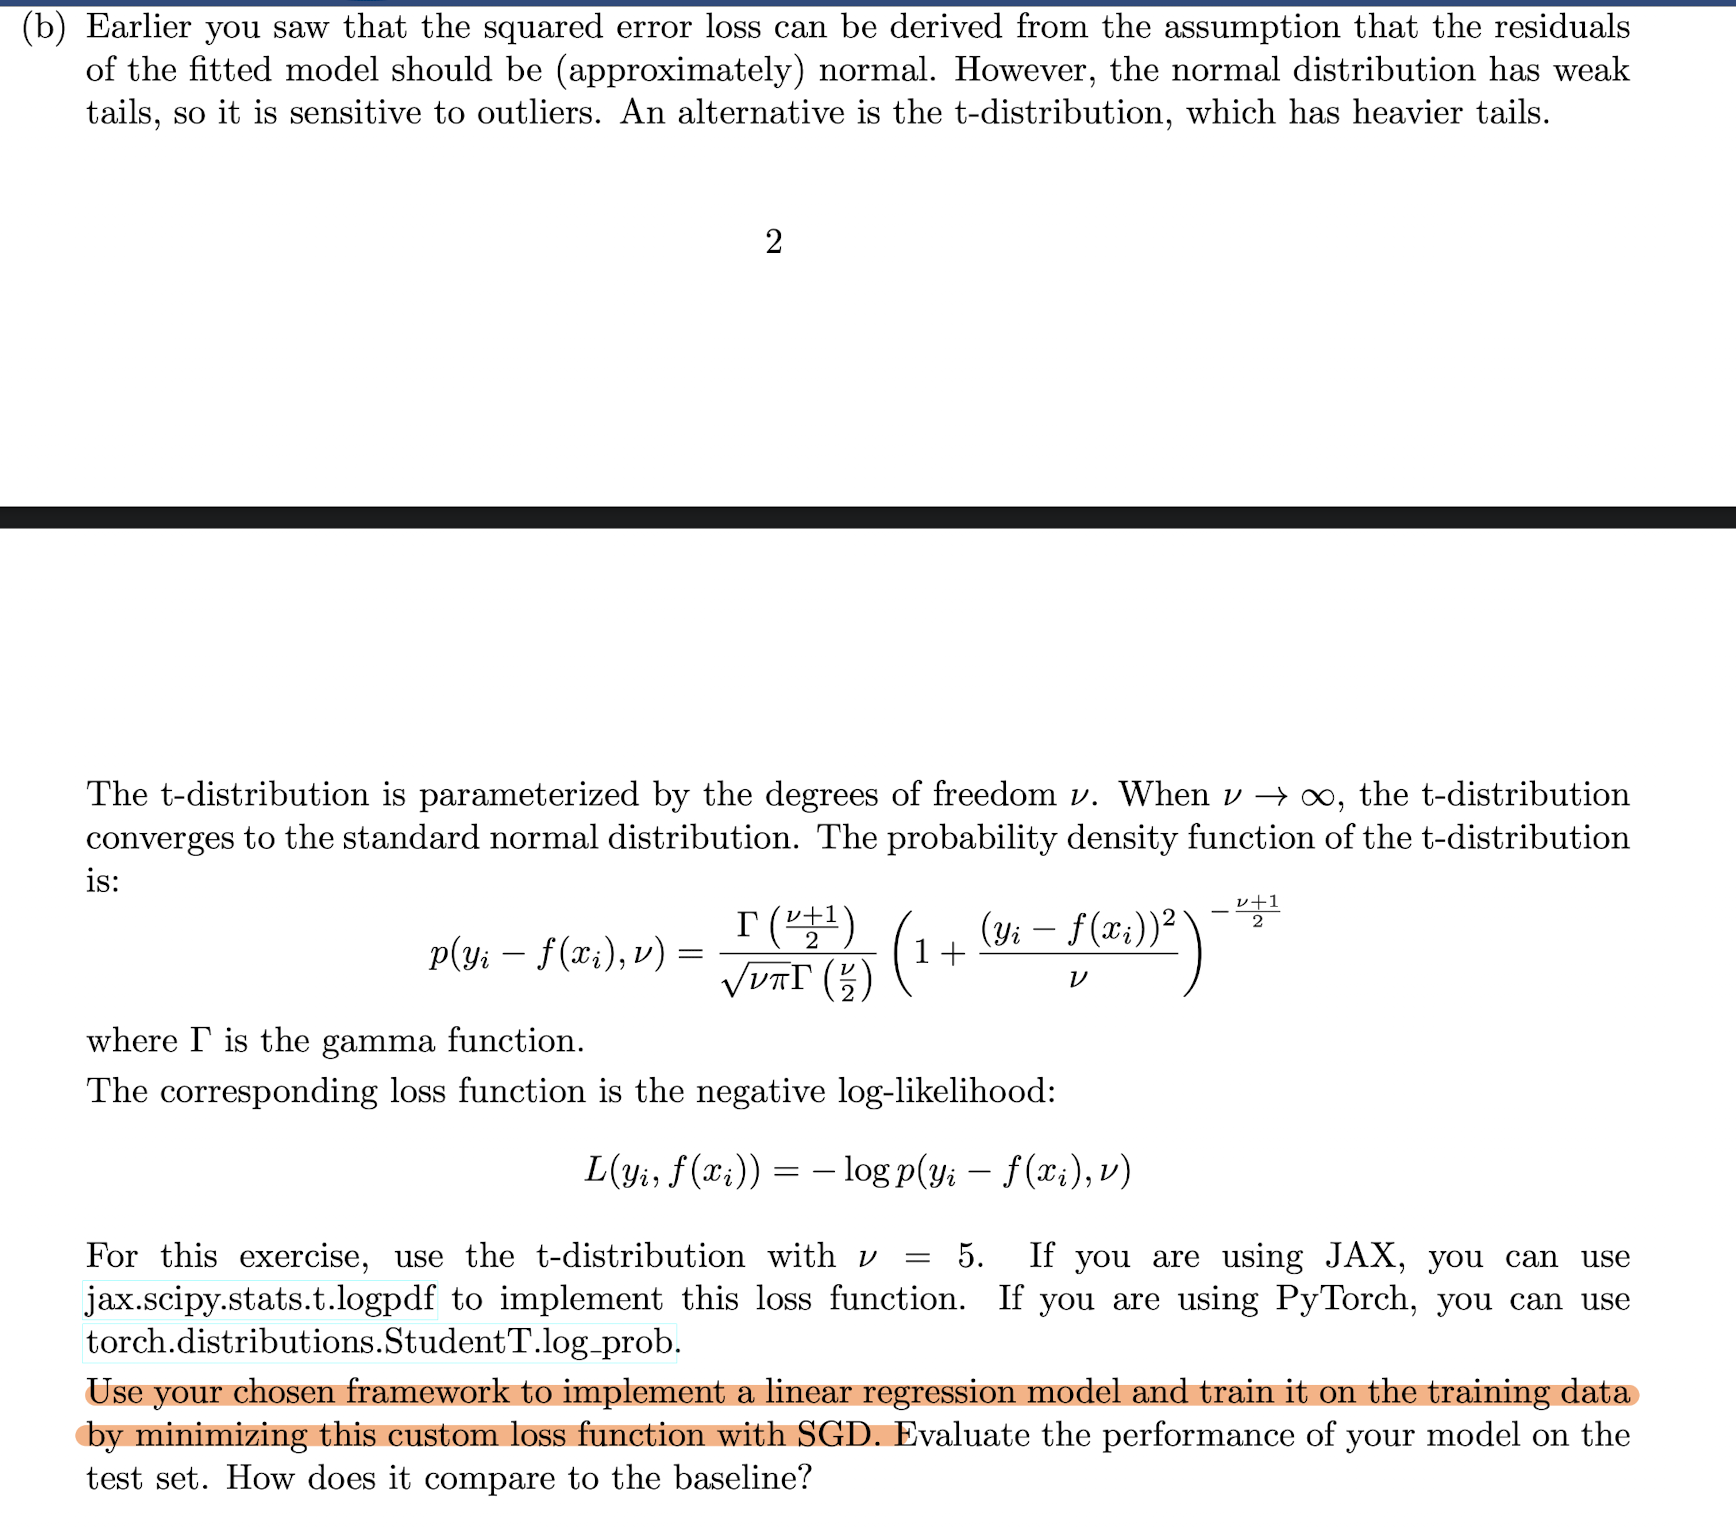

In [112]:
from torch.distributions import StudentT

t_dist = StudentT(df=5.0) 

def student_loss(y, pred):
    return -t_dist.log_prob(y - pred).mean()

In [113]:
w = torch.zeros(n_features, requires_grad=True)
b = torch.zeros(1, requires_grad=True)

optimizer = torch.optim.SGD([w, b], lr=0.1)

n_epochs = 100
batch_size = 50
n = X_train_t.shape[0]

for epoch in range(n_epochs):
    perm = torch.randperm(n)                      # shuffle each epoch does a random permutation of the data
    for i in range(0, n, batch_size): 
        idx = perm[i:i + batch_size] 
        xb, yb = X_train_t[idx], y_train_t[idx]  #obtains the training features and labels to obtain the loss 

        loss = student_loss(yb, f_linear(xb)) #computes the loss using yb and the function we defined earlier

        optimizer.zero_grad()   # clear old gradients
        loss.backward()         # autodiff computes dL/dw and dL/db
        optimizer.step()        # w <- w - lr * grad

    if (epoch + 1) % 20 == 0:
        with torch.no_grad():
            full_loss = student_loss(y_train_t, f_linear(X_train_t))
        print(f"Epoch {epoch+1}: train loss = {full_loss:.4f}")

Epoch 20: train loss = 0.9979
Epoch 40: train loss = 0.9977
Epoch 60: train loss = 0.9977
Epoch 80: train loss = 0.9977
Epoch 100: train loss = 0.9977


In [114]:
with torch.no_grad():
    fit_linear = f_linear(X_test_t)
    pred_mae = mean_absolute_error(y_test, fit_linear.numpy())

print(f"Baseline (sklearn) MAE: {baseline_mae:.4f}")
print(f"Autodiff + SGD MAE:     {pred_mae:.4f}")

Baseline (sklearn) MAE: 0.1954
Autodiff + SGD MAE:     0.1931
